--- Tabela Comparativa de Avaliação de Modelos ---


,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC
1,Decision Tree,0.8863,1.0000,0.7456,0.8543,0.8708
5,Random Forest,0.8857,1.0000,0.7444,0.8535,0.8742
6,Gradient Boosting,0.8847,0.9953,0.7456,0.8525,0.8775
4,SVM,0.8695,0.9521,0.7456,0.8363,0.8729
3,Naïve Bayes,0.8097,0.8926,0.6530,0.7542,0.8412
2,k-NN,0.8008,0.8690,0.6530,0.7456,0.8301
0,Logistic Regression,0.7222,0.6829,0.7069,0.6947,0.7873


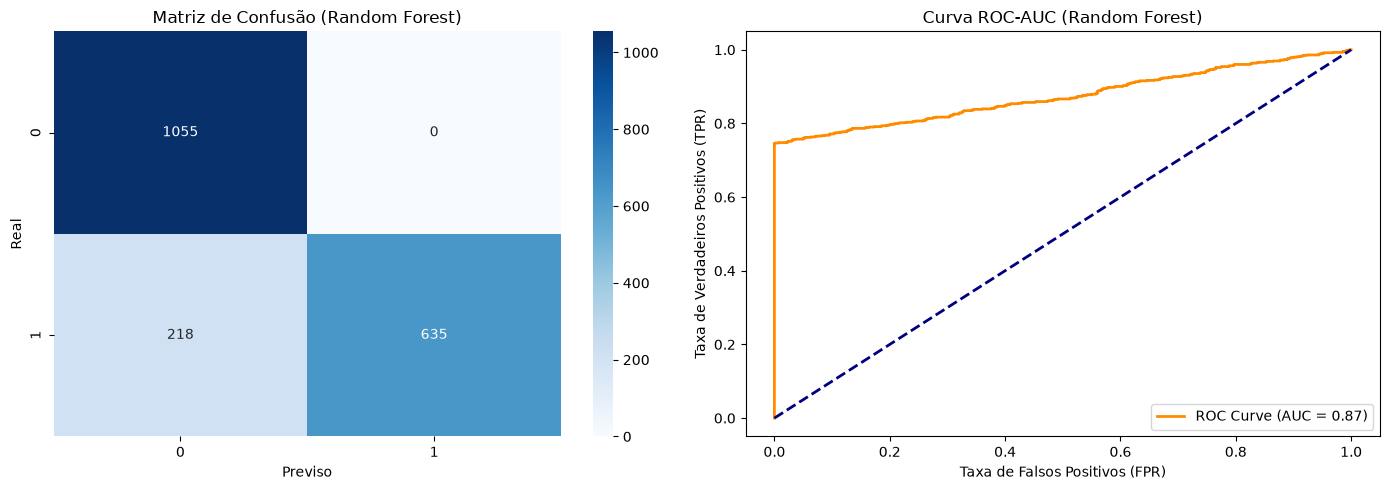

In [1]:
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

# 1. Carregar dados e modelos guardados nos notebooks anteriores
with open('../models/processed_data.pkl', 'rb') as f:
    X_train_prep, X_test_prep, y_train, y_test = pickle.load(f)

with open('../models/trained_models.pkl', 'rb') as f:
    trained_models = pickle.load(f)

# 2. Avaliar cada modelo no conjunto de teste
results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test_prep)
    y_prob = model.predict_proba(X_test_prep)[:, 1] if hasattr(model, "predict_proba") else [0]*len(y_pred)
    
    results.append({
        'Modelo': name,
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred, zero_division=0), 4),
        'Recall': round(recall_score(y_test, y_pred, zero_division=0), 4),
        'F1-Score': round(f1_score(y_test, y_pred, zero_division=0), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_prob), 4)
    })

# 3. Criar tabela comparativa de resultados
results_df = pd.DataFrame(results).sort_values(by='F1-Score', ascending=False)
print("--- Tabela Comparativa de Avaliação de Modelos ---")
display(results_df)

# 4. Matriz de Confusão e Curva ROC do Melhor Modelo (Random Forest)
best_model = trained_models['Random Forest']
y_pred_best = best_model.predict(X_test_prep)
y_prob_best = best_model.predict_proba(X_test_prep)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz de Confusão
sns.heatmap(confusion_matrix(y_test, y_pred_best), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Matriz de Confusão (Random Forest)')
axes[0].set_xlabel('Previso')
axes[0].set_ylabel('Real')

# Curva ROC
fpr, tpr, _ = roc_curve(y_test, y_prob_best)
roc_auc = roc_auc_score(y_test, y_prob_best)

axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.2f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_title('Curva ROC-AUC (Random Forest)')
axes[1].set_xlabel('Taxa de Falsos Positivos (FPR)')
axes[1].set_ylabel('Taxa de Verdadeiros Positivos (TPR)')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

In [2]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# 1. Definir a grelha de hiperparâmetros a otimizar
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [6, 8, 12],
    'min_samples_split': [2, 5]
}

# 2. Instanciar o GridSearchCV com validação cruzada (CV = 3)
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(class_weight='balanced', random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1
)

print("--- A Executar Hyperparameter Tuning (GridSearchCV) ---")
grid_search.fit(X_train_prep, y_train)

# 3. Mostrar os melhores hiperparâmetros encontrados
print("\nMelhores Hiperparâmetros:")
print(grid_search.best_params_)
print(f"Melhor F1-Score no Cross-Validation: {grid_search.best_score_:.4f}")

# 4. Avaliar o modelo otimizado no conjunto de teste
best_rf_model = grid_search.best_estimator_
y_pred_opt = best_rf_model.predict(X_test_prep)

print("\n--- Relatório de Classificação Final (Random Forest Otimizado) ---")
print(classification_report(y_test, y_pred_opt))

--- A Executar Hyperparameter Tuning (GridSearchCV) ---

Melhores Hiperparâmetros:
{'max_depth': 12, 'min_samples_split': 2, 'n_estimators': 150}
Melhor F1-Score no Cross-Validation: 0.8685

--- Relatório de Classificação Final (Random Forest Otimizado) ---
              precision    recall  f1-score   support

           0       0.83      1.00      0.91      1055
           1       1.00      0.75      0.85       853

    accuracy                           0.89      1908
   macro avg       0.91      0.87      0.88      1908
weighted avg       0.90      0.89      0.88      1908



In [1]:
import sys
sys.path.append('../scripts')
from evaluate import evaluate_all_models, tune_random_forest

# 1. Avaliar modelos
results_df, X_train_prep, X_test_prep, y_train, y_test = evaluate_all_models()
display(results_df)

# 2. Executar Hyperparameter Tuning
best_params, best_score, report, best_model = tune_random_forest(X_train_prep, y_train, X_test_prep, y_test)
print("Melhores Hiperparâmetros:", best_params)
print("\n--- Relatório Final ---")
print(report)

,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC
1,Decision Tree,0.8863,1.0000,0.7456,0.8543,0.8708
5,Random Forest,0.8857,1.0000,0.7444,0.8535,0.8742
6,Gradient Boosting,0.8847,0.9953,0.7456,0.8525,0.8775
4,SVM,0.8695,0.9521,0.7456,0.8363,0.8729
3,Naïve Bayes,0.8097,0.8926,0.6530,0.7542,0.8412
2,k-NN,0.8008,0.8690,0.6530,0.7456,0.8301
0,Logistic Regression,0.7222,0.6829,0.7069,0.6947,0.7873


Melhores Hiperparâmetros: {'max_depth': 12, 'min_samples_split': 2, 'n_estimators': 150}

--- Relatório Final ---
              precision    recall  f1-score   support

           0       0.83      1.00      0.91      1055
           1       1.00      0.75      0.85       853

    accuracy                           0.89      1908
   macro avg       0.91      0.87      0.88      1908
weighted avg       0.90      0.89      0.88      1908

